In [7]:
import pandas as pd
import numpy as np
from astropy import units as u
from galpy.orbit import Orbit
from galpy.potential import MWPotential2014
from galpy.actionAngle import actionAngleStaeckel, estimateDeltaStaeckel
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import sys
from pathlib import Path

project_dir = Path.cwd()
if not (project_dir / "plot_style.py").exists():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
from plot_style import *

In [8]:
data = pd.read_csv("../3_spectroscopic_xmatch/GSPSPEC_input_catalogue.csv")
phasespace = [
    data["ra"].to_numpy() * u.degree,
    data["dec"].to_numpy() * u.degree,
    data["dist"].to_numpy() / 1e3 * u.kpc,
    data["pmra"].to_numpy() * u.mas / u.yr,
    data["pmdec"].to_numpy() * u.mas / u.yr,
    data["rv"].to_numpy() * u.km / u.s
]

In [9]:
orbits = Orbit(phasespace, radec=True, ro=8.0, vo=220.0)

jr = orbits.jr(pot=MWPotential2014, analytic=True, type="staeckel")
lz = orbits.Lz()
jz = orbits.jz(pot=MWPotential2014, analytic=True, type="staeckel")

e = orbits.e(pot=MWPotential2014, analytic=True, type="staeckel")
zmax = orbits.zmax(pot=MWPotential2014, analytic=True, type="staeckel")
rperi = orbits.rperi(pot=MWPotential2014, analytic=True, type="staeckel")
rap = orbits.rap(pot=MWPotential2014, analytic=True, type="staeckel")
rguid = orbits.rguiding(pot=MWPotential2014, ro=8.0, vo=220.0, use_physical=True)

orbits_df = pd.DataFrame({
    "gaiadr3_id": np.array(data["gaiadr3_id"]),
    "jr": np.array(jr),
    "lz": np.array(lz),
    "jz": np.array(jz),
    "e": np.array(e),
    "zmax": np.array(zmax),
    "rguid": np.array(rguid)
})

In [10]:
input_data = pd.read_csv("../4_ages/GSPSPEC_dnu_output.csv")
w_orbits = pd.merge(input_data, orbits_df, how="right", on="gaiadr3_id")

In [11]:
# 1. Prepare the 3 features: log10(Jr), log10(Jz), and Lz
# Filter out any non-physical/zero actions before taking log10
valid = (w_orbits["jr"] > 0) & (w_orbits["jz"] > 0) & w_orbits["lz"].notna()
w_orbits_clean = w_orbits.loc[valid].copy()

X = np.column_stack([
    np.log10(w_orbits_clean["jr"]),
    np.log10(w_orbits_clean["jz"]),
    w_orbits_clean["lz"]
])

# 2. Standardise features so Lz (~2000) doesn't dominate log10(J) (~1-3)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Fit a 3-component GMM (Thin Disc, Thick Disc, Halo)
gmm = GaussianMixture(
    n_components=2,
    covariance_type="full",
    n_init=10,
    random_state=42
)
gmm.fit(X_scaled)

# 4. Predict hard labels and membership probabilities
labels = gmm.predict(X_scaled)
probs = gmm.predict_proba(X_scaled)

# 5. Identify which GMM cluster corresponds to Thin, Thick, and Halo
# Transform cluster centres back to physical units to inspect them
centres = scaler.inverse_transform(gmm.means_)
summary = pd.DataFrame(centres, columns=["log10_jr", "log10_jz", "lz"])
summary["weight"] = gmm.weights_
print(summary)

   log10_jr  log10_jz           lz    weight
0  1.124561  0.811115  1786.520538  0.601185
1  1.670900  0.990481  1487.462635  0.398815


In [12]:
# Get posterior probabilities for all rows in X_scaled (shape: N_stars x 2)
probs = gmm.predict_proba(X_scaled)

# Sort component indices by mean log10_jz so index 0 = Thin Disc and index 1 = Thick Disc
centres = scaler.inverse_transform(gmm.means_)
thin_idx, thick_idx = np.argsort(centres[:, 1])  # column 1 is log10_jz

# Assign to new columns in your DataFrame
w_orbits_clean["thin"] = probs[:, thin_idx]
w_orbits_clean["thick"] = probs[:, thick_idx]

# Quick sanity check (all rows should equal 1.0)
print((w_orbits_clean["thin"] + w_orbits_clean["thick"]).describe())

count    2.043000e+04
mean     1.000000e+00
std      2.032322e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64


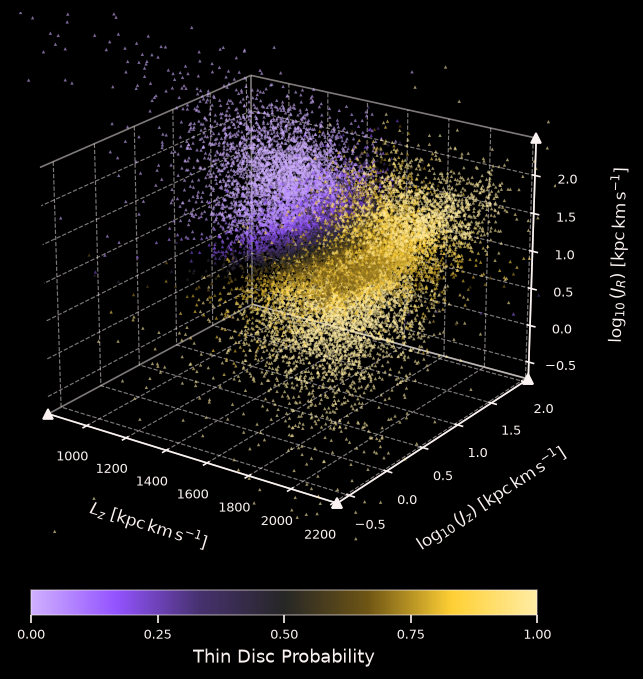

In [15]:
dark()

# 1. Prepare coordinates
x = w_orbits_clean["lz"]
y = np.log10(w_orbits_clean["jz"])
z = np.log10(w_orbits_clean["jr"])
# y = w_orbits_clean["jz"]
# z = w_orbits_clean["jr"]
c = w_orbits_clean["thin"]  # 0 = Thick Disc, 1 = Thin Disc

fig = plt.figure(figsize=(8, 6), facecolor="black")
ax = fig.add_subplot(111, projection="3d", facecolor="black")

# 2. Plot stars coloured by Thin Disc probability
sc = ax.scatter(
    x, y, z,
    c=c,
    cmap=cmap_dark_div,
    s=4,
    alpha=0.6,
    vmin=0,
    vmax=1,
    edgecolors="none",
    depthshade=False
)

# 3. Remove 3D pane background shading and explicitly enable gridlines on every axis
ax.grid(True)
for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis.pane.fill = False
    axis.pane.set_edgecolor(to_rgba(cream, 0.25))
    axis._axinfo["grid"]["color"] = to_rgba(cream, 0.5)
    axis._axinfo["grid"]["linestyle"] = "--"
    axis._axinfo["grid"]["linewidth"] = 0.7

# 4. Trim axis limits to the bulk of the stars (0.5th to 99.5th percentiles)
ax.set_xlim(np.percentile(x, [0.5, 99.5]))
ax.set_ylim(np.percentile(y, [0.5, 99.5]))
ax.set_zlim(np.percentile(z, [0.5, 99.5]))

# Labels, title, and camera angle
ax.set_xlabel(r"$L_z$ [$\mathrm{kpc}\,\mathrm{km}\,\mathrm{s}^{-1}$]", color=cream, labelpad=10)
ax.set_ylabel(r"$\log_{10}(J_z)$ [$\mathrm{kpc}\,\mathrm{km}\,\mathrm{s}^{-1}$]", color=cream, labelpad=10)
ax.set_zlabel(r"$\log_{10}(J_R)$ [$\mathrm{kpc}\,\mathrm{km}\,\mathrm{s}^{-1}$]", color=cream, labelpad=10)
ax.tick_params(colors=cream)
ax.view_init(elev=22, azim=-55)

# 5. Fully opaque colourbar with percentage ticks
cbar = fig.colorbar(sc, ax=ax, shrink=0.55, pad=0.05, orientation="horizontal")
cbar.solids.set(alpha=1.0)
cbar.set_ticks([0.0, 0.25, 0.50, 0.75, 1.0])
cbar.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
cbar.set_label("Thin Disc Probability", color=cream, fontsize=11)
cbar.ax.yaxis.set_tick_params(color=cream)
plt.setp(plt.getp(cbar.ax.axes, "yticklabels"), color=cream)
cbar.outline.set_edgecolor(to_rgba(cream, 0.4))

plt.tight_layout()
plt.savefig("../figures/5_GMM_orbits.png", dpi=200)
plt.show()


In [ ]:
thin_temp = w_orbits[(w_orbits["zmax"] < 0.5) & (w_orbits["e"] < 0.2)]
print(len(thin_temp), len(w_orbits))

6645 20587


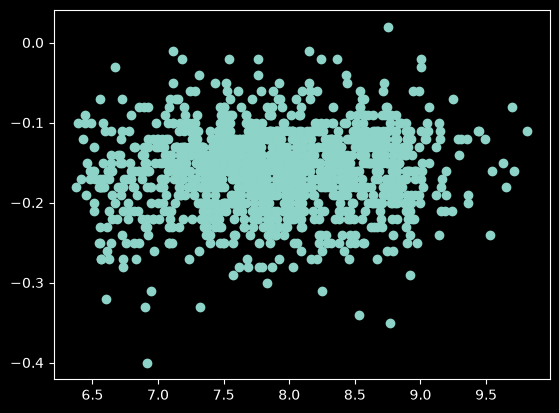

In [ ]:
plt.scatter(thin_temp["rguid"], thin_temp["fe_h"])

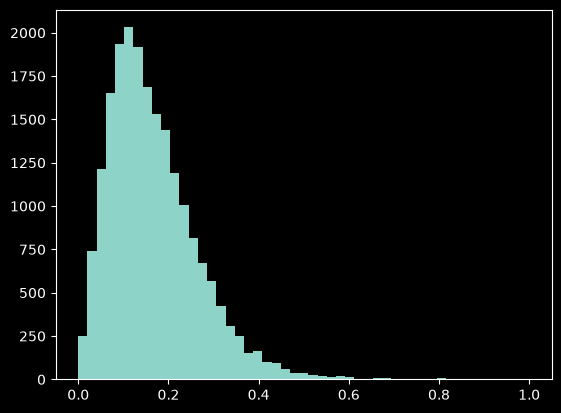

In [ ]:
plt.hist(w_orbits["e"], bins=np.linspace(0, 1, 50))
plt.show()

In [ ]:
sub_orbits = pd.merge(input_data["gaiadr3_id"], w_orbits_clean, how="left", on="gaiadr3_id")
sub_orbits.to_csv("./GSPSPEC_dnu_orbits.csv", index=False)

In [ ]:
print(len(sub_orbits))

3816
